In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

In [16]:
df = pd.read_csv(r"D:\1_Python Programmes\Projects\HDD\data\heart_disease_cleaned.csv")

X = df.drop(columns = ["id","dataset","num"])
y = df["num"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_features:
    X_train[col] = X_train[col].map(
        lambda value: str(value) if pd.notna(value) else np.nan
    )

In [4]:
lr_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/logistic_r_model.pkl")
knn_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/heart_disease_knn.pkl")
dt_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/decision_tree_model.pkl")
rf_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/random_forest_model.pkl")
svm_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/svm_model.pkl")

models = {
    "Logistic Regression": lr_model,
    "KNN (K=16)": knn_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Tuned SVM": svm_model
}

In [17]:
# Stratified 5-Fold Cross-Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "roc_auc": "roc_auc",
    "f1": "f1"
}

# Store results
cv_results = {}

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results[name] = {
        "Mean ROC-AUC": scores["test_roc_auc"].mean(),
        "Std ROC-AUC": scores["test_roc_auc"].std(),
        "Mean F1": scores["test_f1"].mean(),
        "Std F1": scores["test_f1"].std()
    }

# Create comparison DataFrame
cv_comparison = pd.DataFrame(cv_results).T

# Sort by ROC-AUC
cv_comparison = cv_comparison.sort_values(
    by="Mean ROC-AUC",
    ascending=False
)

print(cv_comparison.round(4))

                     Mean ROC-AUC  Std ROC-AUC  Mean F1  Std F1
Tuned SVM                  0.8966       0.0135   0.8431  0.0113
Logistic Regression        0.8959       0.0200   0.8328  0.0092
KNN (K=16)                 0.8807       0.0217   0.8334  0.0191
Random Forest              0.8787       0.0288   0.8331  0.0132
Decision Tree              0.7061       0.0454   0.7370  0.0335


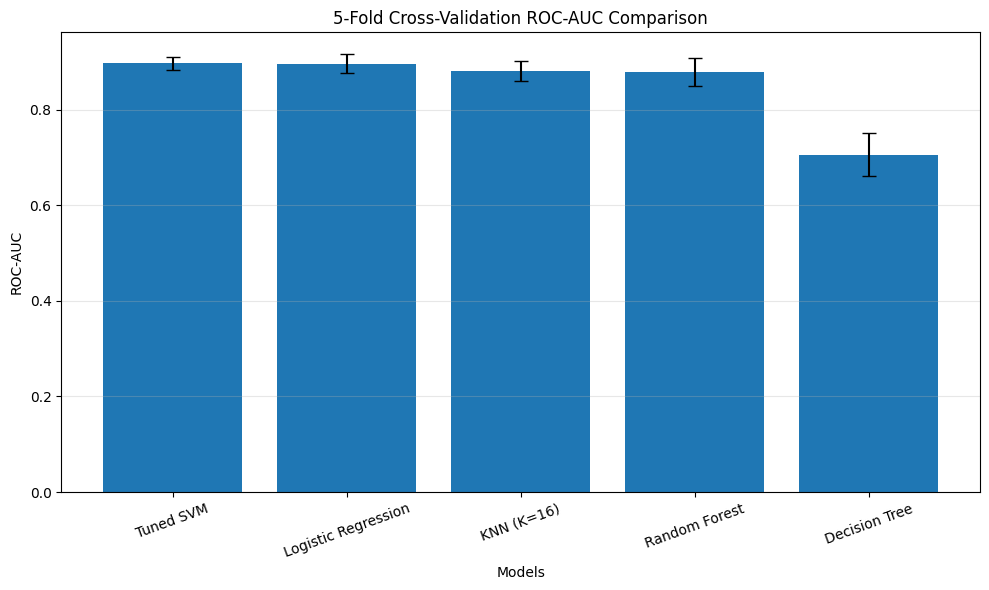

In [23]:
plt.figure(figsize=(10, 6))

plt.bar(
    cv_comparison.index,
    cv_comparison["Mean ROC-AUC"],
    yerr=cv_comparison["Std ROC-AUC"],
    capsize=5
)

plt.ylabel("ROC-AUC")
plt.xlabel("Models")
plt.title("5-Fold Cross-Validation ROC-AUC Comparison")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
# plt.savefig("reports/cv_roc_auc_comparison.png", dpi=300)
plt.show()